In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler, StandardScaler



# Load original CSV files
baseline = pd.read_csv(r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\raw\baseline.csv")
followup = pd.read_csv(r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\raw\followup.csv")

print("Baseline Shape:", baseline.shape)
print("Follow-up Shape:", followup.shape)

display(baseline.head())
display(followup.head())


Baseline Shape: (5000, 8)
Follow-up Shape: (41800, 12)


,usubjid,trt01pn,randfl,ittfl,trtfl,blgfr,blglp1,strata
0,id0001,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
1,id0002,1,Y,Y,Y,27,N,Screening eGFR 45 to <60 mL/min/1.73m2
2,id0003,1,Y,Y,Y,50,N,Screening eGFR 45 to <60 mL/min/1.73m2
3,id0004,0,Y,Y,Y,47,N,Screening eGFR 45 to <60 mL/min/1.73m2
4,id0005,0,Y,Y,Y,75,N,Screening eGFR 60 to <90 mL/min/1.73m2


,usubjid,randfl,ittfl,trtfl,anl01fl,aval,base,paramcd,param,ady,avisitn,avisit
0,id0001,Y,Y,Y,Y,54,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE
1,id0001,Y,Y,Y,Y,51,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3
2,id0001,Y,Y,Y,Y,61,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13
3,id0001,Y,Y,Y,Y,63,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26
4,id0001,Y,Y,Y,Y,53,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52


In [22]:

baseline = baseline.rename(columns={
    "usubjid": "patient_id",
    "trt01pn": "treatment_group",
    "randfl": "randomized_flag",
    "ittfl": "itt_flag",
    "trtfl": "treatment_flag",
    "blgfr": "baseline_egfr",
    "blglp1": "baseline_glp1",
    "strata": "egfr_category"
})

print("Baseline columns:")
print(baseline.columns.tolist())


Baseline columns:
['patient_id', 'treatment_group', 'randomized_flag', 'itt_flag', 'treatment_flag', 'baseline_egfr', 'baseline_glp1', 'egfr_category']


In [23]:

followup = followup.rename(columns={
    "usubjid": "patient_id",
    "randfl": "randomized_flag",
    "ittfl": "itt_flag",
    "trtfl": "treatment_flag",
    "anl01fl": "analysis_flag",
    "aval": "egfr_value",
    "base": "baseline_egfr",
    "paramcd": "parameter_code",
    "param": "parameter_name",
    "ady": "study_day",
    "avisitn": "visit_number",
    "avisit": "visit_label"
})

print("Follow-up columns:")
print(followup.columns.tolist())


Follow-up columns:
['patient_id', 'randomized_flag', 'itt_flag', 'treatment_flag', 'analysis_flag', 'egfr_value', 'baseline_egfr', 'parameter_code', 'parameter_name', 'study_day', 'visit_number', 'visit_label']


In [24]:

# Verify patient identifiers
assert baseline["patient_id"].is_unique
assert baseline["patient_id"].notna().all()

# Merge followup with baseline
merged = pd.merge(
    followup,
    baseline,
    on="patient_id",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_followup", "_baseline")
)

print("Merged Dataset Shape:", merged.shape)

display(merged.head())



Merged Dataset Shape: (41800, 20)


,patient_id,randomized_flag_followup,itt_flag_followup,treatment_flag_followup,analysis_flag,egfr_value,baseline_egfr_followup,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,randomized_flag_baseline,itt_flag_baseline,treatment_flag_baseline,baseline_egfr_baseline,baseline_glp1,egfr_category,_merge
0,id0001,Y,Y,Y,Y,54,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
1,id0001,Y,Y,Y,Y,51,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
2,id0001,Y,Y,Y,Y,61,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
3,id0001,Y,Y,Y,Y,63,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both
4,id0001,Y,Y,Y,Y,53,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52,0,Y,Y,Y,54,N,Screening eGFR 45 to <60 mL/min/1.73m2,both


In [25]:

# Check matched and unmatched records
print("Merge Status:")
print(merged["_merge"].value_counts())

# Find unmatched records
unmatched = merged[
    merged["_merge"] == "left_only"
]

print("\nUnmatched records:", len(unmatched))

# Check number of unique patients
print("Unique patients:", merged["patient_id"].nunique())

# Verify no follow-up rows were lost
assert len(merged) == len(followup)

# Verify all records matched
assert (merged["_merge"] == "both").all()

print("\nIntegration validation successful!")


Merge Status:
_merge
both          41800
left_only         0
right_only        0
Name: count, dtype: int64

Unmatched records: 0
Unique patients: 5000

Integration validation successful!


In [26]:

# Compare baseline eGFR from both datasets
egfr_match = merged["baseline_egfr_followup"].equals(
    merged["baseline_egfr_baseline"]
)

print("Baseline eGFR values match:", egfr_match)

# Stop if the values do not match
assert egfr_match, "Baseline eGFR mismatch detected!"


Baseline eGFR values match: True


In [27]:

flag_pairs = [
    ("randomized_flag_followup", "randomized_flag_baseline"),
    ("itt_flag_followup", "itt_flag_baseline"),
    ("treatment_flag_followup", "treatment_flag_baseline")
]

# Check whether paired attributes match
for followup_col, baseline_col in flag_pairs:

    matches = merged[followup_col].equals(
        merged[baseline_col]
    )

    print(f"{followup_col} matches {baseline_col}: {matches}")


randomized_flag_followup matches randomized_flag_baseline: True
itt_flag_followup matches itt_flag_baseline: True
treatment_flag_followup matches treatment_flag_baseline: True


In [28]:

cleaned_data = merged.copy()

# Remove duplicated baseline eGFR
if egfr_match:
    cleaned_data = cleaned_data.drop(
        columns=["baseline_egfr_followup"]
    )

    cleaned_data = cleaned_data.rename(
        columns={"baseline_egfr_baseline": "baseline_egfr"}
    )

# Remove identical duplicated flags
for followup_col, baseline_col in flag_pairs:

    if cleaned_data[followup_col].equals(
        cleaned_data[baseline_col]
    ):
        cleaned_data = cleaned_data.drop(
            columns=[baseline_col]
        )

        cleaned_data = cleaned_data.rename(
            columns={
                followup_col: followup_col.replace(
                    "_followup", ""
                )
            }
        )

    else:
        print("Mismatch found. Both columns retained:", followup_col)

# Remove merge indicator
cleaned_data = cleaned_data.drop(columns=["_merge"])

print("Cleaned dataset shape:", cleaned_data.shape)
print("\nColumns:")
print(cleaned_data.columns.tolist())

display(cleaned_data.head())


Cleaned dataset shape: (41800, 15)

Columns:
['patient_id', 'randomized_flag', 'itt_flag', 'treatment_flag', 'analysis_flag', 'egfr_value', 'parameter_code', 'parameter_name', 'study_day', 'visit_number', 'visit_label', 'treatment_group', 'baseline_egfr', 'baseline_glp1', 'egfr_category']


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,baseline_egfr,baseline_glp1,egfr_category
0,id0001,Y,Y,Y,Y,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
1,id0001,Y,Y,Y,Y,51,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
2,id0001,Y,Y,Y,Y,61,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
3,id0001,Y,Y,Y,Y,63,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
4,id0001,Y,Y,Y,Y,53,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2


In [29]:

# Count missing values
print("Missing Values:")
print(cleaned_data.isnull().sum())

# Check analysis flag distribution
print("\nAnalysis Flag Distribution:")
print(
    cleaned_data["analysis_flag"].value_counts(
        dropna=False
    )
)

# Inspect records with missing analysis flags
missing_flags = cleaned_data[
    cleaned_data["analysis_flag"].isna()
]

display(
    missing_flags[
        ["patient_id", "visit_label", "study_day", "egfr_value"]
    ].head(10)
)

# Confirm eGFR measurements are present
print(
    "\nMissing eGFR measurements:",
    cleaned_data["egfr_value"].isna().sum()
)


Missing Values:
patient_id           0
randomized_flag      0
itt_flag             0
treatment_flag       0
analysis_flag      800
egfr_value           0
parameter_code       0
parameter_name       0
study_day            0
visit_number         0
visit_label          0
treatment_group      0
baseline_egfr        0
baseline_glp1        0
egfr_category        0
dtype: int64

Analysis Flag Distribution:
analysis_flag
Y      41000
NaN      800
Name: count, dtype: int64


,patient_id,visit_label,study_day,egfr_value
32,id0004,WEEK 130,909,36
92,id0012,WEEK 13,88,61
141,id0017,WEEK 130,906,55
282,id0035,WEEK 26,180,63
439,id0054,WEEK 156,1091,41
467,id0058,WEEK 3,16,60
524,id0064,WEEK 156,1090,53
530,id0065,WEEK 52,362,52
642,id0079,WEEK 26,178,38
790,id0096,WEEK 52,362,52



Missing eGFR measurements: 0


In [30]:

# Select numerical measurements
numeric_columns = [
    "baseline_egfr",
    "egfr_value"
]

# Create a copy
normalized_data = cleaned_data.copy()

# Initialize scaler
minmax_scaler = MinMaxScaler()

# Apply normalization
normalized_data[numeric_columns] = minmax_scaler.fit_transform(
    cleaned_data[numeric_columns]
)

print("Min-Max Normalized Data:")
display(normalized_data[numeric_columns].head())

print("\nMinimum values:")
print(normalized_data[numeric_columns].min())

print("\nMaximum values:")
print(normalized_data[numeric_columns].max())


Min-Max Normalized Data:


,baseline_egfr,egfr_value
0,0.440367,0.440367
1,0.440367,0.412844
2,0.440367,0.504587
3,0.440367,0.522936
4,0.440367,0.431193



Minimum values:
baseline_egfr    0.0
egfr_value       0.0
dtype: float64

Maximum values:
baseline_egfr    1.0
egfr_value       1.0
dtype: float64


In [31]:

standardized_data = cleaned_data.copy()

# Initialize scaler
standard_scaler = StandardScaler()

# Apply standardization
standardized_data[numeric_columns] = standard_scaler.fit_transform(
    cleaned_data[numeric_columns]
)

print("Standardized Data:")
display(standardized_data[numeric_columns].head())

print("\nMean:")
print(standardized_data[numeric_columns].mean())

print("\nStandard Deviation:")
print(
    standardized_data[numeric_columns].std(ddof=0)
)


Standardized Data:


,baseline_egfr,egfr_value
0,-0.095561,0.332701
1,-0.095561,0.016223
2,-0.095561,1.071149
3,-0.095561,1.282134
4,-0.095561,0.227208



Mean:
baseline_egfr   -2.617789e-17
egfr_value      -7.326410e-17
dtype: float64

Standard Deviation:
baseline_egfr    1.0
egfr_value       1.0
dtype: float64


In [32]:

comparison_data = pd.DataFrame({
    "Original eGFR": cleaned_data["egfr_value"],
    "Min-Max eGFR": normalized_data["egfr_value"],
    "Z-Score eGFR": standardized_data["egfr_value"]
})

print("Transformation Comparison:")

display(comparison_data.head(10))


Transformation Comparison:


,Original eGFR,Min-Max eGFR,Z-Score eGFR
0,54,0.440367,0.332701
1,51,0.412844,0.016223
2,61,0.504587,1.071149
3,63,0.522936,1.282134
4,53,0.431193,0.227208
5,47,0.376147,-0.405748
6,37,0.284404,-1.460674
7,58,0.477064,0.754671
8,59,0.486239,0.860164
9,27,0.192661,-2.515601


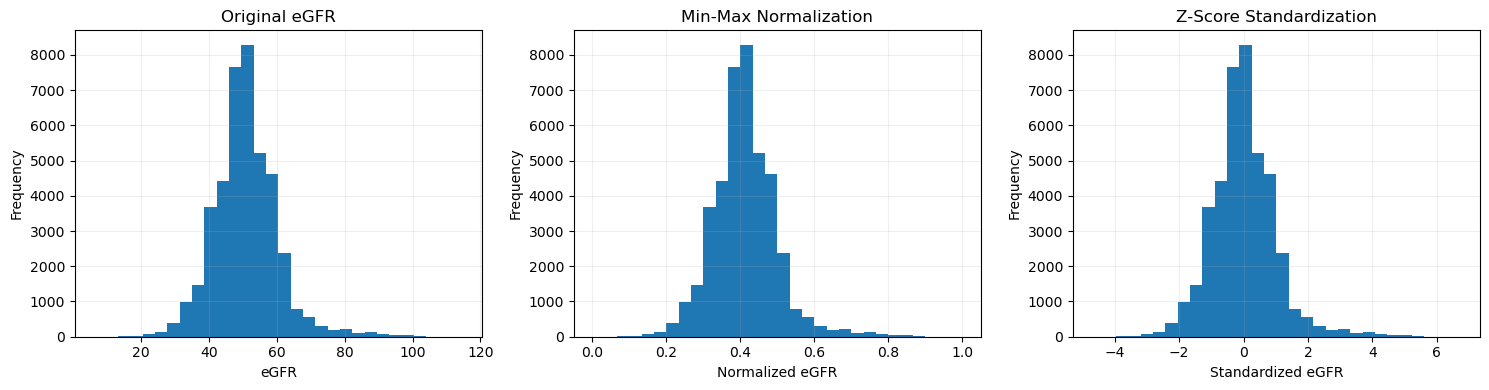

In [33]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(
    cleaned_data["egfr_value"],
    bins=30
)
axes[0].set_title("Original eGFR")
axes[0].set_xlabel("eGFR")

axes[1].hist(
    normalized_data["egfr_value"],
    bins=30
)
axes[1].set_title("Min-Max Normalization")
axes[1].set_xlabel("Normalized eGFR")

axes[2].hist(
    standardized_data["egfr_value"],
    bins=30
)
axes[2].set_title("Z-Score Standardization")
axes[2].set_xlabel("Standardized eGFR")

for ax in axes:
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [34]:

# Confirm expected records are preserved
assert len(cleaned_data) == len(followup)

# Confirm all patients are retained
assert (
    cleaned_data["patient_id"].nunique()
    == baseline["patient_id"].nunique()
)

# Check missing measurements
assert cleaned_data["egfr_value"].notna().all()

# Check chronological study days are valid numbers
assert pd.api.types.is_numeric_dtype(
    cleaned_data["study_day"]
)

# Sort observations by patient and study day
cleaned_data = cleaned_data.sort_values(
    by=["patient_id", "study_day"]
).reset_index(drop=True)

print("Final Dataset Shape:", cleaned_data.shape)
print("Unique Patients:", cleaned_data["patient_id"].nunique())
print("Missing eGFR:", cleaned_data["egfr_value"].isna().sum())

display(cleaned_data.head())



Final Dataset Shape: (41800, 15)
Unique Patients: 5000
Missing eGFR: 0


,patient_id,randomized_flag,itt_flag,treatment_flag,analysis_flag,egfr_value,parameter_code,parameter_name,study_day,visit_number,visit_label,treatment_group,baseline_egfr,baseline_glp1,egfr_category
0,id0001,Y,Y,Y,Y,54,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,1,0,BASELINE,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
1,id0001,Y,Y,Y,Y,51,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,22,3,WEEK 3,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
2,id0001,Y,Y,Y,Y,61,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,91,13,WEEK 13,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
3,id0001,Y,Y,Y,Y,63,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,183,26,WEEK 26,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2
4,id0001,Y,Y,Y,Y,53,GFRBSCRT,GFR from Creatinine Adjusted for BSA (mL/min/1...,362,52,WEEK 52,0,54,N,Screening eGFR 45 to <60 mL/min/1.73m2


In [35]:


from pathlib import Path

# Main project directory
project_dir = Path(
    r"C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES"
)

# Dataset paths
raw_dir = project_dir / "datasets" / "raw"
processed_dir = project_dir / "datasets" / "processed"

processed_dir.mkdir(parents=True, exist_ok=True)

# Load
baseline = pd.read_csv(raw_dir / "baseline.csv")
followup = pd.read_csv(raw_dir / "followup.csv")

# Save after completing preprocessing
output_path = processed_dir / "smart_c_merged.csv"

cleaned_data.to_csv(output_path, index=False)

print("Saved to:", output_path)



Saved to: C:\Users\DELL\Desktop\CRONIC KIDNEY DISEASES\datasets\processed\smart_c_merged.csv
